### **BAGIAN 2: PEMBENTUKAN CITRA DAN RUANG WARNA**


---

**Tujuan bagian**: menentukan syarat pemotretan berdasarkan model kamera, lalu
menemukan kanal warna yang paling mampu memisahkan bercak dari daun sehat pada
berbagai kondisi cahaya.

In [1]:
# Konfigurasi Drive

from google.colab import drive
import os
import sys

drive.mount('/content/drive')
BASE_DIR = "/content/drive/MyDrive/simuteh-1032"
os.chdir(BASE_DIR)
sys.path.append(os.path.join(BASE_DIR, "src"))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

Mounted at /content/drive


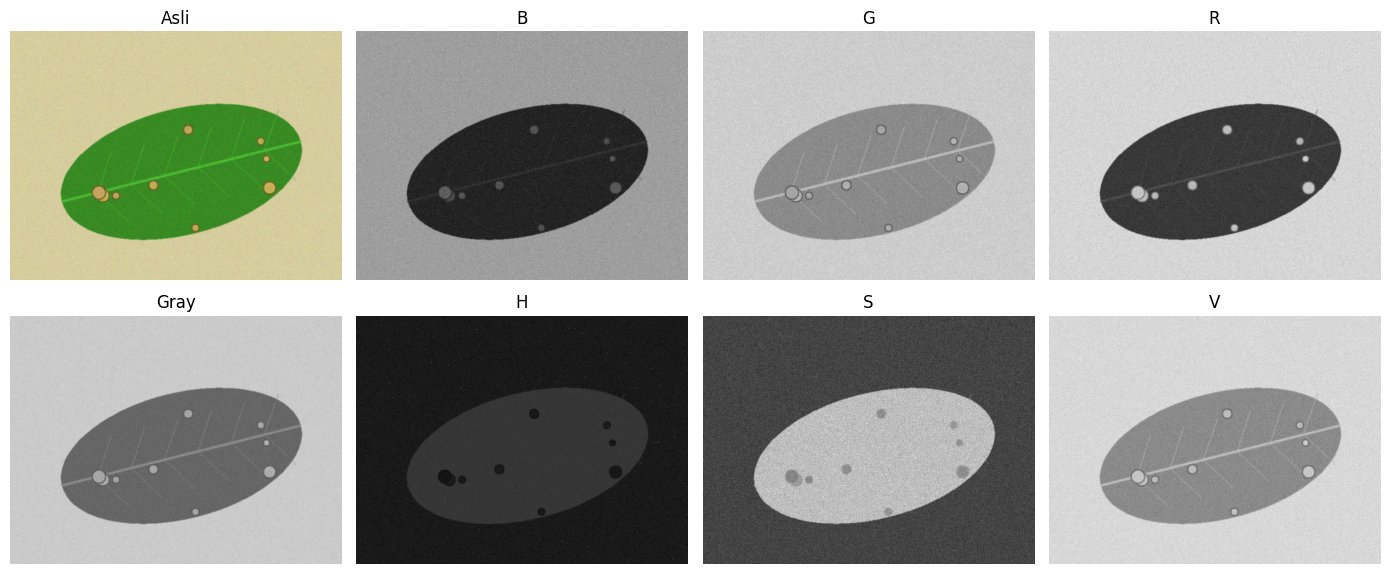

--- Kontras Bercak (KB) Citra teh_041 (Normal) ---
KB kanal B   : 3.34
KB kanal G   : 0.19
KB kanal R   : 9.67
KB kanal Gray: 4.18
KB kanal H   : 8.37
KB kanal S   : 2.40
KB kanal V   : 1.90


In [4]:
# 2.3 Pemisahan Kanal Warna & Hitung Kontras Bercak (KB)
# Menggunakan citra kelas berat, kondisi normal (teh_041.png)
nama = "teh_041.png"
img = baca(f"data/sintetis/citra/{nama}")
md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)

kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}

# Tampilkan visualisasi 8 citra kanal
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()), baris=2, ukuran=(14, 6))
plt.savefig("hasil/b2_pemisahan_kanal.png")
plt.show()

# Cetak nilai Kontras Bercak (KB) tiap kanal
print("--- Kontras Bercak (KB) Citra teh_041 (Normal) ---")
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

In [3]:
# 2.4 Eksperimen Sampling & Kuantisasi

print("=== EXPERIMEN SAMPLING (Resolusi) ===")
for fx in [0.5, 0.2, 0.1, 0.05]:
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1], interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx:<4}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")

print("\n=== EXPERIMEN KUANTISASI (Bit) ===")
for k in [1, 2, 3, 4, 8]:
    langkah = 256 // (2**k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant)):2d} level, KB={kontras_bercak(kuant, md, mb):.2f}")

=== EXPERIMEN SAMPLING (Resolusi) ===
fx=0.5 : ukuran (240, 320), KB=4.88
fx=0.2 : ukuran (96, 128), KB=4.10
fx=0.1 : ukuran (48, 64), KB=2.87
fx=0.05: ukuran (24, 32), KB=1.29

=== EXPERIMEN KUANTISASI (Bit) ===
k=1:  2 level, KB=3.81
k=2:  3 level, KB=3.81
k=3:  6 level, KB=2.72
k=4: 11 level, KB=3.88
k=8: 155 level, KB=4.18


In [6]:
# 2.5 Uji di seluruh kondisi cahaya

def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img)
    h, s, v = cv2.split(hsv)
    return {
        "B": b, "G": g, "R": r,
        "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "H": h, "S": s, "V": v
    }

label = pd.read_csv("data/sintetis/label.csv")
baris = []

for _, d in label[label.kelas == "berat"].iterrows():
    im = baca(f"data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris.append(kb)

tabel_kb = pd.DataFrame(baris).groupby("kondisi").mean().round(2)
print("=== Rerata KB Kelas Berat Per Kondisi Cahaya ===")
print(tabel_kb)
tabel_kb.to_csv("hasil/b2_kb_kanal.csv")

=== Rerata KB Kelas Berat Per Kondisi Cahaya ===
                   B     G      R  Gray     H     S     V
kondisi                                                  
bayangan        1.55  0.83   5.36  2.17  3.90  0.77  1.55
gelap           1.60  2.00  12.42  5.55  6.88  0.81  3.93
kontras_rendah  0.76  0.66   4.19  2.48  2.03  0.10  1.68
normal          2.44  0.96   8.76  4.43  6.39  1.39  2.46
terang          1.30  1.23   6.59  3.86  4.32  0.26  2.45


=== Rerata KB Kelas Ringan Per Kondisi Cahaya ===
                   B     G     R  Gray     H     S     V
kondisi                                                 
bayangan        1.08  0.63  4.72  1.34  4.78  0.64  0.86
gelap           0.68  0.36  8.10  2.57  5.37  0.98  1.55
kontras_rendah  0.40  0.28  3.04  1.14  1.84  0.30  0.68
normal          1.49  0.35  7.24  2.62  6.37  1.14  1.09
terang          2.12  0.53  7.01  3.57  5.69  0.90  1.89


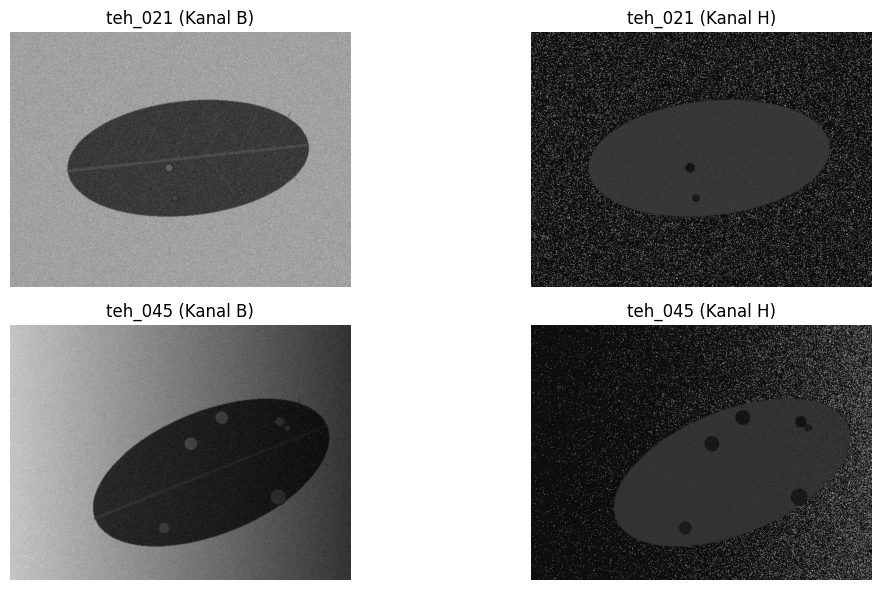

In [7]:
# 2.6 Evaluasi kelas ringan & kanal terbaik

baris_ringan = []
for _, d in label[label.kelas == "ringan"].iterrows():
    im = baca(f"data/sintetis/citra/{d.nama_file}")
    m_d = cv2.imread(f"data/sintetis/mask_daun/{d.nama_file}", 0)
    m_b = cv2.imread(f"data/sintetis/mask_bercak/{d.nama_file}", 0)

    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
    kb["kondisi"] = d.kondisi_cahaya
    baris_ringan.append(kb)

tabel_kb_ringan = pd.DataFrame(baris_ringan).groupby("kondisi").mean().round(2)
print("=== Rerata KB Kelas Ringan Per Kondisi Cahaya ===")
print(tabel_kb_ringan)

# Tampilkan perbandingan kanal terbaik untuk teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
img_021 = baca("data/sintetis/citra/teh_021.png")
img_045 = baca("data/sintetis/citra/teh_045.png")

tampil(
    [cv2.split(img_021)[0], cv2.split(cv2.cvtColor(img_021, cv2.COLOR_BGR2HSV))[0],
     cv2.split(img_045)[0], cv2.split(cv2.cvtColor(img_045, cv2.COLOR_BGR2HSV))[0]],
    ["teh_021 (Kanal B)", "teh_021 (Kanal H)", "teh_045 (Kanal B)", "teh_045 (Kanal H)"],
    baris=2, ukuran=(12, 6)
)
plt.savefig("hasil/b2_kanal_terbaik.png")
plt.show()